> Notebook-friendly copy of `part-I/1.4-matplotlib-and-xarray-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Run the setup cell below first. Label every axis with its unit.

Exercise 1 works on a real global-temperature record, and the last four exercises work differently: each shows a figure made from a real dataset and asks you to rebuild it. Get as close as you can, and read the hints one at a time rather than all at once.

In [2]:
# Pre-supplied: run this first.
import numpy as np
import matplotlib.pyplot as plt

## Exercise 1: NASA's real global-temperature record

The file cached below is NASA GISS's monthly global-mean surface temperature anomaly (°C,
relative to a 1951–1980 baseline), one row per year since 1880, one column per calendar month.
A handful of recent months are still missing, marked `***`.

Wrap the twelve month columns in an xarray `DataArray` with dims `("year", "month")` and a `units`
attribute, then draw two figures: the annual mean as a line against year, and the full
`(year, month)` array with xarray's own `.plot()`. In a comment, compare what the warming trend
looks like read month by month against the single annual line.

In [3]:
# Pre-supplied: download the data file and cache it locally.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/nasa_gistemp_global_temp_anomaly.csv",
    known_hash="sha256:6cfa44e7bbacd9b12cb10bdd64b3182c2735fa3f3a95688e1f7bc8e5dfcece93",
    fname="nasa_gistemp_global_temp_anomaly.csv",
    path=pooch.os_cache("mlees"),
)

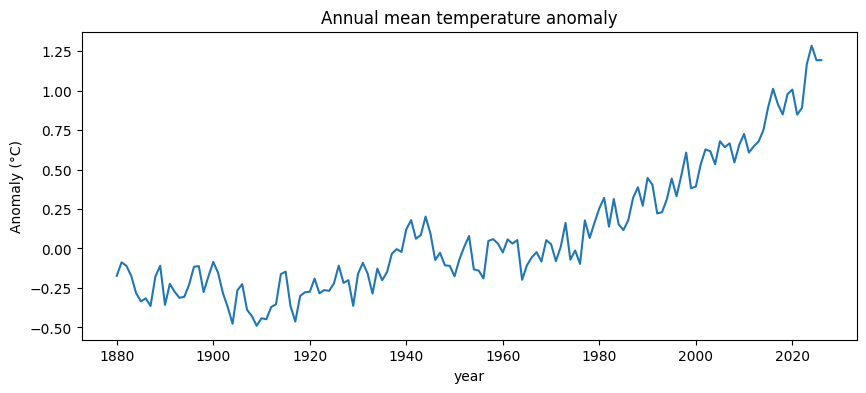

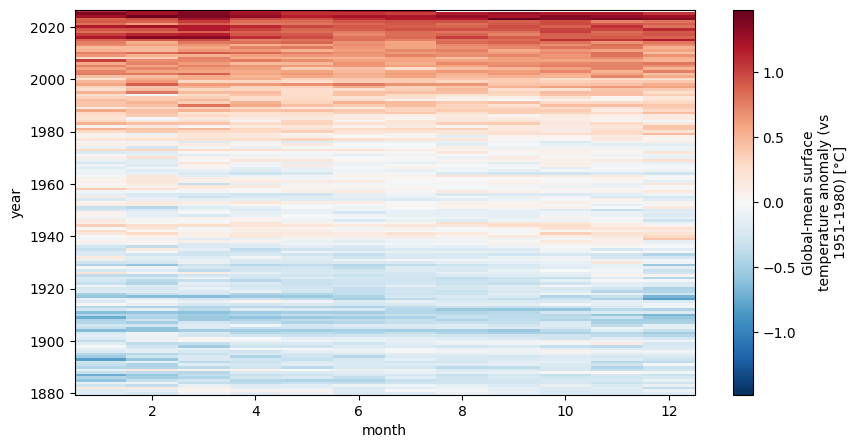

In [29]:
# Exercise 1: NASA's real global-temperature record
# Hint: load the file with
#       np.genfromtxt(path, skip_header=1, delimiter=",", names=True,
#                     missing_values="***", filling_values=np.nan)
#       -- names=True reads the header row, so the columns are data["Year"], data["Jan"], ...
# Hint: np.column_stack((data["Jan"], data["Feb"], ..., data["Dec"])) puts the twelve month
#       columns side by side as one (year, month) array
# Hint: the coordinates are data["Year"] and np.arange(1, 13)
# Hint: .mean(dim="month") skips the missing months on its own
# Hint: .plot() on the 2D DataArray draws a pcolormesh, and labels the colorbar from the
#       long_name and units attributes

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# 1. Carica il file (*** = dati mancanti -> NaN)
data = np.genfromtxt(path, skip_header=1, delimiter=",", names=True,
                     missing_values="***", filling_values=np.nan)

# 2. Matrice (year, month) con le 12 colonne dei mesi
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
values = np.column_stack([data[m] for m in months])

# 3. DataArray con coordinate e attributi
temp = xr.DataArray(
    values,
    dims=("year", "month"),
    coords={"year": data["Year"].astype(int), "month": np.arange(1, 13)},
    name="temperature_anomaly",
    attrs={"units": "°C",
           "long_name": "Global-mean surface temperature anomaly (vs 1951-1980)"},
)

# 4. Figura 1: media annuale
annual = temp.mean(dim="month")   # xarray salta i NaN di default
fig, ax = plt.subplots(figsize=(10, 4))
annual.plot(ax=ax)
ax.set_ylabel("Anomaly (°C)")
ax.set_title("Annual mean temperature anomaly")
plt.show()

# 5. Figura 2: array completo (year, month) con pcolormesh
fig, ax = plt.subplots(figsize=(10, 5))
temp.plot(ax=ax, x="month", y="year")
plt.show()

# Comment: ...

## Replicating plots

The four exercises below each show a figure built from a real dataset and ask you to rebuild it
as closely as you can. The data arrive through a pre-supplied `pooch` cell; everything after that
is yours.

Work towards the target one element at a time — get the data onto the axes first, then the
coordinates, then the colours, then the labels — rather than trying to write the whole cell in
one go.

## Exercise 2: Global surface air temperature and its zonal mean

The three files cached below hold one snapshot of surface air temperature from the
[NCEP/NCAR atmospheric reanalysis 1](https://psl.noaa.gov/data/gridded/data.ncep.reanalysis.html),
as plain numpy arrays: `lon` (192 longitudes), `lat` (94 latitudes, running north to south), and
`temp_kelvin`, the field itself with shape `(94, 192)` — **in kelvin**.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-global-temperature.png" alt="A filled contour map of global surface air temperature in magma colours with a white dashed contour at minus ten degrees, beside a line plot of the zonal mean against latitude" width="100%">

<em>The figure to replicate. Left: the field as filled contours, with a single white contour drawn
at −10 °C. Right: the zonal mean — the average along longitude — against latitude.</em>


Rebuild it, and say in a comment which hemisphere's winter this snapshot was taken in, and how
the zonal mean tells you.

In [30]:
# Pre-supplied: download the three arrays and cache them locally.
import pooch

In [31]:
base_url = "https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/"

In [32]:
path_lon = pooch.retrieve(
    url=base_url + "ncep_global_temp_lon.npy",
    known_hash="sha256:eaf54b88dd89279d3034da17fe8470dc2c841bf9fa89b2aa741dacff9c326cdb",
    fname="ncep_global_temp_lon.npy",
    path=pooch.os_cache("mlees"),
)
path_lat = pooch.retrieve(
    url=base_url + "ncep_global_temp_lat.npy",
    known_hash="sha256:af1f438080460e1fca4583b2ec19b44285a3d3776e4d21b8da9b6e162906c88a",
    fname="ncep_global_temp_lat.npy",
    path=pooch.os_cache("mlees"),
)
path_temp = pooch.retrieve(
    url=base_url + "ncep_global_temp_kelvin.npy",
    known_hash="sha256:e040ca257334708b43e86398e09a5669fcf051179ecf5dcd278f758d67beed20",
    fname="ncep_global_temp_kelvin.npy",
    path=pooch.os_cache("mlees"),
)

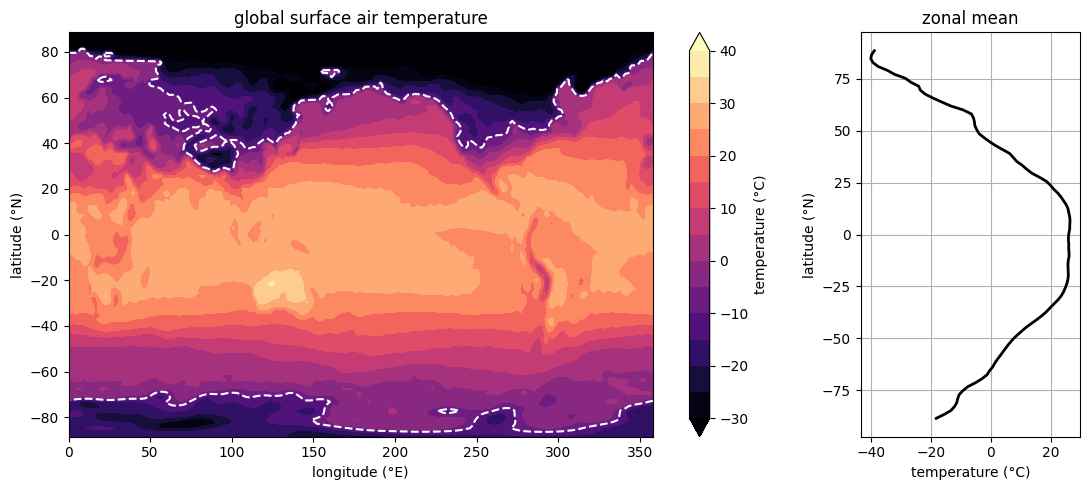

In [37]:
# Your solution here
# Hint: np.load each file, then subtract 273.15 to go from kelvin to degrees celsius
# Hint: plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [5, 1.5]})
#       -- width_ratios is what makes the left panel wider than the right one
# Hint: the left panel is contourf with cmap="magma", levels=np.linspace(-30, 40, 15) and
#       extend="both", with contour at levels=[-10] and colors="w" on top; matplotlib dashes a
#       contour at a negative level on its own, which is where the dashed white line comes from
# Hint: the right panel is the mean along longitude, np.nanmean(temp_celsius, axis=1), plotted
#       against latitude -- so the temperature goes on the x-axis
# Hint: label both panels and the colorbar, and finish with plt.tight_layout()

import numpy as np
import matplotlib.pyplot as plt

# 1. Carica i dati e converti da kelvin a Celsius
lon = np.load(path_lon)
lat = np.load(path_lat)
temp_celsius = np.load(path_temp) - 273.15   # shape (94, 192)

# 2. Figura: pannello sinistro più largo del destro
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5),
                               gridspec_kw={"width_ratios": [5, 1.5]})

# 3. Sinistra: campo con filled contours + contorno bianco a -10 °C
cf = ax1.contourf(lon, lat, temp_celsius, cmap="magma",
                  levels=np.linspace(-30, 40, 15), extend="both")
ax1.contour(lon, lat, temp_celsius, levels=[-10], colors="w")
ax1.set_title("global surface air temperature")
ax1.set_xlabel("longitude (°E)")
ax1.set_ylabel("latitude (°N)")
fig.colorbar(cf, ax=ax1, label="temperature (°C)")

# 4. Destra: media zonale (lungo la longitudine) vs latitudine
zonal_mean = np.nanmean(temp_celsius, axis=1)   # shape (94,)
ax2.plot(zonal_mean, lat, "k", lw=2)
ax2.set_title("zonal mean")
ax2.set_xlabel("temperature (°C)")
ax2.set_ylabel("latitude (°N)")
ax2.grid(True)

plt.tight_layout()
plt.show()

# The snapshot was taken in the northern hemisphere's winter (southern summer).
# The zonal mean tells us: the temperature drops much more steeply toward the
# North Pole (about -40 °C at 80°N) than toward the South Pole (about -20 °C
# at -80°N), and the warmest latitudes are shifted slightly north of the
# equator...


## Exercise 3: Historic significant earthquakes

The file cached below is NOAA's catalog of significant earthquakes, reaching back to 2150 BCE:
one row per event, tab-separated, 47 columns. The four you need are at positions 8
(`FOCAL_DEPTH`, km), 9 (`EQ_PRIMARY`, magnitude), 20 (`LATITUDE`) and 21 (`LONGITUDE`).

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-earthquakes-scatter.png" alt="A scatter plot of earthquake longitude against latitude, coloured by the base-10 logarithm of focal depth and sized by magnitude" width="100%">

<em>The figure to replicate: every event as one point, coloured by the base-10 logarithm of its
focal depth and sized by its magnitude. No coastline is drawn — the plate boundaries are the
data.</em>


Rebuild it, and in a comment name the feature of the Earth that the points trace out.

In [1]:
# Pre-supplied: download the data file and cache it locally.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/signif.txt.tsv",
    known_hash="sha256:f27e00d335f64ffaf437e74a8efb54f9154d40b417ff93fefb0fd64856e6d345",
    fname="signif.txt.tsv",
    path=pooch.os_cache("mlees"),
)

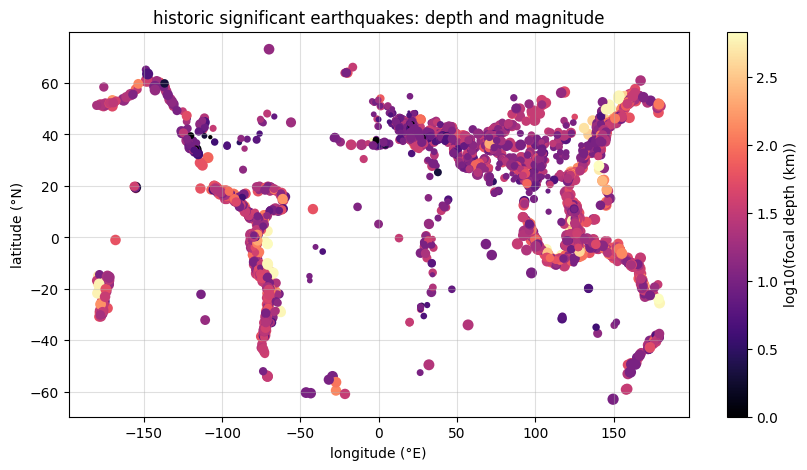

In [3]:
# Your solution here
# Hint: np.genfromtxt(path, delimiter="\t", skip_header=1) loads the whole file; every
#       non-numeric field becomes NaN, which is what you want here. Pull the four columns out
#       by position -- the focal depth, for example, is arr[:, 8]
# Hint: keep only the rows where depth and magnitude are both above zero and latitude and
#       longitude are not NaN. & combines two masks element-wise ("and"), and ~ flips one
#       ("not"), so ~np.isnan(latitude) is True wherever the latitude is present
# Hint: colour the points by np.log10 of the focal depth -- the base-10 logarithm, applied
#       element-wise, which spreads out depths from under a kilometre to several hundred --
#       and set the point area to the square of the magnitude
# Hint: add a labelled colorbar, axis labels, a title, and a dotted grid

import numpy as np
import matplotlib.pyplot as plt

# 1. Carica il file
arr = np.genfromtxt(path, delimiter="\t", skip_header=1)

# 2. Seleziona le colonne di interesse
depth = arr[:, 8]
mag = arr[:, 9]
latitude = arr[:, 20]
longitude = arr[:, 21]

# 3. Seleziona i dati validi
mask = (depth > 0) & (mag > 0) & ~np.isnan(latitude) & ~np.isnan(longitude)

# 4. Colora i punti con np.log10 of the focal lentgh
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(longitude[mask], latitude[mask], c=np.log10(depth[mask]), s=mag
           [mask] ** 2, cmap="magma", edgecolor="none")
ax.set_title("historic significant earthquakes: depth and magnitude")
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
fig.colorbar(ax.collections[0], ax=ax, label="log10(focal depth (km))")
ax.grid(True, alpha = 0.4)

# Commento:
# Il grafico mostra la magnitudo e la profondità dei sismi signficativi
# avvenuti 2150 BCE"



## Exercise 4: Antarctic sea ice, summer against winter

Two real snapshots of Antarctic sea ice concentration from NOAA/NSIDC are cached below, as
`path_winter` (1 August 2017) and `path_summer` (31 December 2017). Each holds
`seaice_conc_cdr`, the ice concentration as a fraction from 0 to 1, on a south polar
stereographic grid — its coordinates are 2D `latitude`/`longitude` arrays rather than simple 1D
dimensions, so xarray's own `.plot()` will not label it cleanly.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-seaice.png" alt="Two south polar stereographic maps of Antarctic sea ice concentration, one in austral winter with a wide ice ring and one in austral summer with much less ice" width="100%">

<em>The figure to replicate: the same field on the same projection at two dates, with the land drawn
in grey beneath the ice and one colorbar shared by both panels.</em>


Rebuild it, and say which date shows more ice.

In [4]:
# Pre-supplied: download the data files and cache them locally.
import pooch

path_winter = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/seaice_conc_daily_sh_f17_20170801_v03r01.nc",
    known_hash="sha256:1ff50bca1e6249a9b2fcd9d9466e31bdb5be650243f99c7319ab2ce625b87ce7",
    fname="seaice_conc_daily_sh_f17_20170801_v03r01.nc",
    path=pooch.os_cache("mlees"),
)
path_summer = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/seaice_conc_daily_sh_f17_20171231_v03r01.nc",
    known_hash="sha256:309418969ad09f42b8104589bcb86de4ed353a5742fef9385baec174c7d55e66",
    fname="seaice_conc_daily_sh_f17_20171231_v03r01.nc",
    path=pooch.os_cache("mlees"),
)

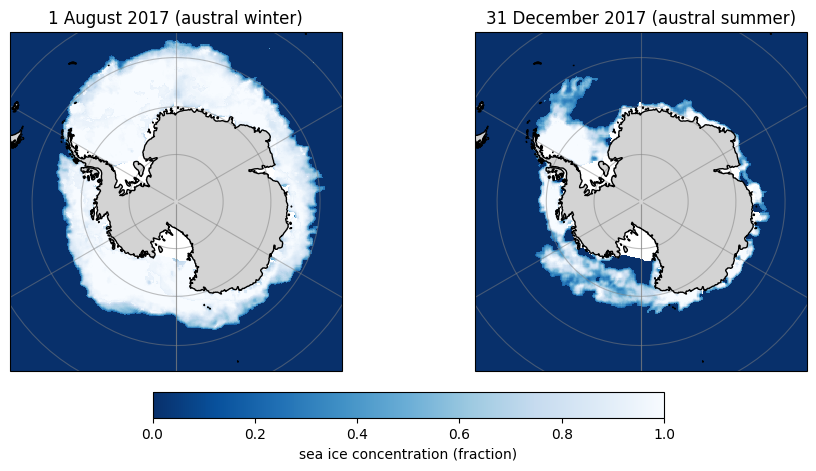

In [12]:
# Your solution here
# Hint: open each file with xr.open_dataset and select the single time step with .isel(time=0)
# Hint: the valid concentration range is 0-1; a few cells carry flag values above 1
#       (land, coastal, missing) -- mask them out first with da.where(da <= 1)
# Hint: build a figure with two ccrs.SouthPolarStereo() axes:
#       plt.subplots(1, 2, subplot_kw={"projection": ccrs.SouthPolarStereo()})
# Hint: ax.set_extent([-180, 180, -90, -55], ccrs.PlateCarree()) crops each axes to the
#       Southern Ocean instead of the whole hemisphere
# Hint: since latitude/longitude are 2D, plot with
#       ax.pcolormesh(ds["longitude"], ds["latitude"], masked, transform=ccrs.PlateCarree())
#       rather than xarray's own .plot()
# Hint: pass vmin=0 and vmax=1 to both pcolormesh calls, so a colour means the same
#       concentration in both panels and one colorbar can serve both
# Hint: add cfeature.LAND under the data and gridlines; fig.colorbar(pcm, ax=axes, label=...)
#       takes the whole array of axes and draws one colorbar for both panels

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Apri i file e seleziona l'unico time step
ds_winter = xr.open_dataset(path_winter).isel(time=0)
ds_summer = xr.open_dataset(path_summer).isel(time=0)

# 2. Maschera i valori flag (> 1: terra, costa, mancanti)
conc_winter = ds_winter["seaice_conc_cdr"].where(ds_winter["seaice_conc_cdr"] <= 1)
conc_summer = ds_summer["seaice_conc_cdr"].where(ds_summer["seaice_conc_cdr"] <= 1)

# 3. Figura con due assi in proiezione polare sud
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5),
                         subplot_kw={"projection": ccrs.SouthPolarStereo()})

panels = [(axes[0], ds_winter, conc_winter, "1 August 2017 (austral winter)"),
          (axes[1], ds_summer, conc_summer, "31 December 2017 (austral summer)")]

for ax, ds, conc, title in panels:
    ax.set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=0)
    ax.gridlines(color="grey", alpha=0.5)
    pcm = ax.pcolormesh(ds["longitude"], ds["latitude"], conc,
                        transform=ccrs.PlateCarree(),
                        cmap="Blues_r", vmin=0, vmax=1)
    ax.coastlines(color="k", zorder=3)
    ax.set_title(title)

# 4. Una sola colorbar condivisa
fig.colorbar(pcm, ax=axes, orientation="horizontal", shrink=0.6,
             pad=0.05, label="sea ice concentration (fraction)")
plt.show()

# The winter snapshot (1 August) shows far more sea ice: it extends around
# the whole continent, while in summer (31 December) it has retreated to
# a few patches, mainly in the Weddell Sea and along the Antarctic Peninsula.

# Commento:
# La data che mostra una quantità nettamente maggiore di ghiaccio è l'1 Agosto 2017 (Inverno australe),
# dove si nota una vasta area ad anello coperta da ghiaccio marino intorno al continente antartico.


## Exercise 5: The 2014 earthquakes over North America

The file cached below is the real USGS earthquake catalog for 2014 — one row per event
worldwide, with latitude, longitude, depth and magnitude in columns 1 to 4. The target figure
keeps the whole catalog and lets the map extent do the selecting, so what you see is a window
onto a global dataset rather than one cropped to North America in advance.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-earthquakes-map.png" alt="A Robinson-projection map of North America with state boundaries, lakes and rivers, and earthquake locations coloured by depth" width="90%">

<em>The figure to replicate: magnitude 4 and above, on a Robinson projection cropped to North and
Central America, over land, ocean, lake, river and state-boundary features.</em>


Rebuild it.

In [13]:
# Pre-supplied: download the data file and cache it locally.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/usgs_earthquakes_2014.csv",
    known_hash="sha256:84d455fb96dc8f782fba4b5fbe56cb8970cab678f07c766fcba1b1c4674de1b1",
    fname="usgs_earthquakes_2014.csv",
    path=pooch.os_cache("mlees"),
)

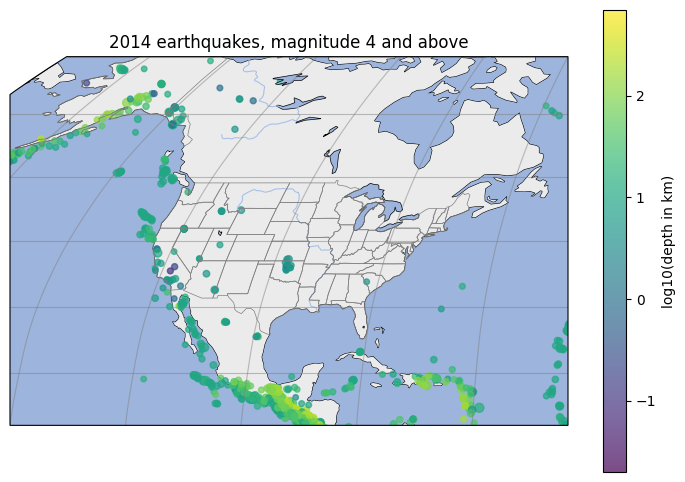

In [17]:
# Your solution here
# Hint: load the four numeric columns with
#       np.genfromtxt(path, delimiter=",", skip_header=1, usecols=(1, 2, 3, 4))
#       -- usecols skips the text columns (time, place, ...) mixed in with the numbers
# Hint: keep mag >= 4 and depth_km > 0 (a few events are recorded at exactly 0 km, which
#       np.log10 cannot take); combine the two conditions into one mask with & ("and")
# Hint: fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()})
# Hint: ax.set_extent([-140, -60, 12, 70], ccrs.PlateCarree()) crops to the window shown
# Hint: the features are cfeature.LAND, cfeature.OCEAN, cfeature.LAKES, cfeature.RIVERS and
#       cfeature.STATES; add_feature takes edgecolor, facecolor and linewidth, and STATES
#       reads better in gray at a thin linewidth
# Hint: ax.scatter(longitude, latitude, transform=ccrs.PlateCarree(),
#                  c=np.log10(depth_km), s=mag ** 2)
#       -- transform tells cartopy the coordinates are plain lon/lat, not already projected
# Hint: finish with ax.gridlines, a labelled colorbar, and a title



import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Carica le 4 colonne numeriche: latitude, longitude, depth, magnitude
data = np.genfromtxt(path, delimiter=",", skip_header=1, usecols=(1, 2, 3, 4))
latitude, longitude, depth_km, mag = data.T

# 2. Maschera: magnitudo >= 4 e profondità > 0 (per il log10)
mask = (mag >= 4) & (depth_km > 0)
latitude, longitude, depth_km, mag = (latitude[mask], longitude[mask],
                                      depth_km[mask], mag[mask])

# 3. Mappa in proiezione Robinson, ritagliata su Nord/Centro America
fig, ax = plt.subplots(figsize=(9, 6),
                       subplot_kw={"projection": ccrs.Robinson()})
ax.set_extent([-140, -60, 12, 70], ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor="0.92", edgecolor="k", linewidth=0.8)
ax.add_feature(cfeature.OCEAN, facecolor="#9db4dc")
ax.add_feature(cfeature.LAKES, facecolor="#9db4dc", edgecolor="k", linewidth=0.5)
ax.add_feature(cfeature.RIVERS, edgecolor="#a9c1e8", linewidth=0.8)
ax.add_feature(cfeature.STATES, edgecolor="gray", facecolor="none", linewidth=0.5)

# 4. Terremoti: colore = log10(profondità), dimensione = magnitudo^2
sc = ax.scatter(longitude, latitude, transform=ccrs.PlateCarree(),
                c=np.log10(depth_km), s=mag ** 2, cmap="viridis", alpha=0.7)

ax.gridlines(color="grey", alpha=0.5)
fig.colorbar(sc, ax=ax, label="log10(depth in km)")
ax.set_title("2014 earthquakes, magnitude 4 and above")
plt.show()
